# A14 — Combined Pose + Keypoint Confidence for Ugly Recording Detection

This notebook merges:

- `A14_keypoint.ipynb`: keypoint confidence branch
- `A14_pose.ipynb`: pose confidence branch

The final predictor uses **both pose confidence and keypoint confidence**. It predicts recording quality from only the first `c = 10` frames, so it can be used before the exercise starts.

The final MLflow model returns:

- predicted pose confidence
- predicted keypoint confidence
- combined recording-quality score
- practical decision: `accept`, `warn`, or `reject`

## Imports, settings, paths

In [1]:
from pathlib import Path
import os
import random
import warnings
import json
import copy
import time
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import joblib

from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import mlflow
import mlflow.pytorch
import mlflow.pyfunc
from mlflow.tracking import MlflowClient

from dotenv import load_dotenv
from os import getenv

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# A14 setup
SEQ_LEN = 10
N_SPLITS = 10
VALIDATION_SPLIT = 0.10

# Training defaults
EPOCHS = 120
PATIENCE = 15
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

# Practical thresholds.
# These are initial suggestions and should be calibrated with your manual good/bad/ugly labels.
ACCEPT_THRESHOLD = 0.70
WARN_THRESHOLD = 0.60

# Weighting for final combined score.
# Combined score = POSE_WEIGHT * pose_score + KEYPOINT_WEIGHT * keypoint_score
POSE_WEIGHT = 0.50
KEYPOINT_WEIGHT = 0.50

# Candidate locations for MoveNet CSV files.
MOVENET_DIR_CANDIDATES = [
    Path("../../data/processed/Good_vs_Bad_movenet/csv_output"),
    Path("../../data/processed/movenet/csv_output"),
    Path("../../data/processed/MoveNet/csv_output"),
    Path("../../data/raw/movenet/csv_output"),
    Path("../../../data/processed/Good_vs_Bad_movenet/csv_output"),
]

MOVENET_DIR = None

for candidate in MOVENET_DIR_CANDIDATES:
    if candidate.exists() and len(list(candidate.glob("*.csv"))) > 0:
        MOVENET_DIR = candidate
        break

if MOVENET_DIR is None:
    raise FileNotFoundError(
        "Could not find a MoveNet CSV directory. "
        "Update MOVENET_DIR_CANDIDATES or set MOVENET_DIR manually."
    )

# Output locations
output_dir = Path("reporting/results")
artifact_dir = Path("reporting/artifacts")

output_dir.mkdir(parents=True, exist_ok=True)
artifact_dir.mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Using MoveNet directory:", MOVENET_DIR)
print("Number of CSV files:", len(list(MOVENET_DIR.glob("*.csv"))))

c:\Users\Kim\software engineering\year 4\LP3\4DT907\machine_learning_project_4dt907\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Using MoveNet directory: ..\..\data\processed\Good_vs_Bad_movenet\csv_output
Number of CSV files: 114


## MLflow setup

In [2]:
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A14_combined_pose_keypoint_confidence"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

client = MlflowClient()

2026/05/18 15:15:00 INFO mlflow.tracking.fluent: Experiment with name 'A14_combined_pose_keypoint_confidence' does not exist. Creating a new experiment.


MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A14_combined_pose_keypoint_confidence


## Objective labeling criteria

This notebook creates objective confidence labels from the MoveNet output.

For every recording, two whole-recording confidence labels are calculated:

1. **Keypoint confidence score**
   - Mean confidence across all selected keypoints and all frames.

2. **Pose confidence score**
   - If the CSV contains an explicit pose-confidence column, that column is used.
   - If no explicit pose-confidence column exists, the pose confidence is approximated as the mean keypoint confidence per frame and then averaged over the whole recording.

The combined target is:

`combined_confidence = 0.5 * pose_confidence + 0.5 * keypoint_confidence`

The model input is only the first `c = 10` frames, because the practical goal is to decide whether a recording will become ugly before the exercise starts.

## MoveNet loading helpers

In [3]:
FRAME_COL_CANDIDATES = [
    "frame_index",
    "frame",
    "frame_id",
    "Frame",
    "FrameID",
    "FrameNo",
    "frame_no",
    "image_id",
    "image_index",
]

POSE_SCORE_CANDIDATES = [
    "pose_score",
    "pose_confidence",
    "movenet_score",
    "movenet_pose_score",
    "score",
    "confidence",
]

MOVENET_TO_ASSIGNMENT = {
    "nose": "head",
    "left_shoulder": "left_shoulder",
    "left_elbow": "left_elbow",
    "right_shoulder": "right_shoulder",
    "right_elbow": "right_elbow",
    "left_wrist": "left_hand",
    "right_wrist": "right_hand",
    "left_hip": "left_hip",
    "right_hip": "right_hip",
    "left_knee": "left_knee",
    "right_knee": "right_knee",
    "left_ankle": "left_foot",
    "right_ankle": "right_foot",
}

JOINTS_13 = list(MOVENET_TO_ASSIGNMENT.values())

COORD_COLS = []
SCORE_COLS = []

for joint in JOINTS_13:
    COORD_COLS.extend([f"{joint}_x", f"{joint}_y"])
    SCORE_COLS.append(f"{joint}_score")


def strip_columns(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    return df


def find_frame_col(df: pd.DataFrame) -> str:
    for col in FRAME_COL_CANDIDATES:
        if col in df.columns:
            return col

    raise ValueError(f"No frame column found. Candidates: {FRAME_COL_CANDIDATES}")


def find_pose_score_col(df: pd.DataFrame) -> str | None:
    for col in POSE_SCORE_CANDIDATES:
        if col in df.columns:
            return col

    return None


def stem_base(csv_path: Path) -> str:
    return csv_path.stem


def load_movenet_as_assignment_df(csv_path: str | Path) -> pd.DataFrame:
    """
    Converts a MoveNet CSV to the assignment's 13-joint format.

    Output includes:
    - frame_index
    - 13 joints with x, y, and score
    - pose_score if available or approximated
    """
    df = pd.read_csv(csv_path)
    df = strip_columns(df)

    frame_col = find_frame_col(df)
    pose_col = find_pose_score_col(df)

    out = pd.DataFrame()
    out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

    if "timestamp_ms" in df.columns:
        out["timestamp_ms"] = df["timestamp_ms"]

    for movenet_joint, assignment_joint in MOVENET_TO_ASSIGNMENT.items():
        for suffix in ["x", "y", "score"]:
            src = f"{movenet_joint}_{suffix}"
            dst = f"{assignment_joint}_{suffix}"

            if src in df.columns:
                out[dst] = pd.to_numeric(df[src], errors="coerce")
            elif dst in df.columns:
                out[dst] = pd.to_numeric(df[dst], errors="coerce")
            else:
                raise ValueError(
                    f"Missing column '{src}' or '{dst}' in {csv_path}. "
                    "The combined A14 model needs x, y, and score columns."
                )

    if pose_col is not None:
        out["pose_score"] = pd.to_numeric(df[pose_col], errors="coerce")
        out["pose_score_source"] = "explicit_pose_column"
    else:
        # Fallback:
        # If there is no explicit pose confidence score, approximate frame pose confidence
        # as the mean confidence over all keypoints in that frame.
        out["pose_score"] = out[SCORE_COLS].mean(axis=1)
        out["pose_score_source"] = "mean_keypoint_fallback"

    out = out.sort_values("frame_index").reset_index(drop=True)
    return out

## Load recordings and calculate whole-recording labels

In [4]:
def calculate_recording_confidence_targets(df: pd.DataFrame) -> dict:
    """
    Calculates objective whole-recording confidence targets.

    Main targets:
    - target_pose_confidence
    - target_keypoint_confidence
    - target_combined_confidence

    Extra diagnostics:
    - min_keypoint_confidence
    - p10_keypoint_confidence
    - fraction_keypoints_below_030
    - fraction_frames_with_any_keypoint_below_030
    """
    keypoint_scores = df[SCORE_COLS].to_numpy(dtype=np.float32)
    pose_scores = df["pose_score"].to_numpy(dtype=np.float32)

    target_keypoint_confidence = float(np.nanmean(keypoint_scores))
    target_pose_confidence = float(np.nanmean(pose_scores))

    target_combined_confidence = (
        POSE_WEIGHT * target_pose_confidence
        + KEYPOINT_WEIGHT * target_keypoint_confidence
    )

    min_keypoint_confidence = float(np.nanmin(keypoint_scores))
    p10_keypoint_confidence = float(np.nanpercentile(keypoint_scores, 10))

    below_030 = keypoint_scores < 0.30
    fraction_keypoints_below_030 = float(np.nanmean(below_030))

    frame_has_low_keypoint = np.any(below_030, axis=1)
    fraction_frames_with_any_keypoint_below_030 = float(np.mean(frame_has_low_keypoint))

    return {
        "target_pose_confidence": target_pose_confidence,
        "target_keypoint_confidence": target_keypoint_confidence,
        "target_combined_confidence": target_combined_confidence,
        "min_keypoint_confidence": min_keypoint_confidence,
        "p10_keypoint_confidence": p10_keypoint_confidence,
        "fraction_keypoints_below_030": fraction_keypoints_below_030,
        "fraction_frames_with_any_keypoint_below_030": fraction_frames_with_any_keypoint_below_030,
        "pose_score_source": df["pose_score_source"].iloc[0],
    }


def load_all_recordings(movenet_dir: Path) -> tuple[pd.DataFrame, dict[str, pd.DataFrame]]:
    rows = []
    sequence_dfs = {}

    csv_files = sorted(movenet_dir.glob("*.csv"))
    print("Found MoveNet CSV files:", len(csv_files))

    for csv_path in csv_files:
        sequence_id = stem_base(csv_path)

        try:
            df = load_movenet_as_assignment_df(csv_path)

            required_cols = SCORE_COLS + ["pose_score"]
            df = df.dropna(subset=required_cols).copy()

            if len(df) < SEQ_LEN:
                rows.append({
                    "sequence_id": sequence_id,
                    "path": str(csv_path),
                    "kept": False,
                    "reason": "too_short",
                    "n_frames": len(df),
                })
                continue

            label_info = calculate_recording_confidence_targets(df)

            sequence_dfs[sequence_id] = df

            rows.append({
                "sequence_id": sequence_id,
                "path": str(csv_path),
                "kept": True,
                "reason": "ok",
                "n_frames": len(df),
                **label_info,
            })

        except Exception as e:
            rows.append({
                "sequence_id": sequence_id,
                "path": str(csv_path),
                "kept": False,
                "reason": f"error: {e}",
                "n_frames": np.nan,
            })

    catalog_df = pd.DataFrame(rows)
    return catalog_df, sequence_dfs


catalog_df, sequence_dfs = load_all_recordings(MOVENET_DIR)

catalog_path = output_dir / "a14_combined_pose_keypoint_confidence_labels.csv"
catalog_df.to_csv(catalog_path, index=False)

display(catalog_df.head())

kept_catalog_df = catalog_df[catalog_df["kept"]].copy().reset_index(drop=True)

print("Saved labels to:", catalog_path)
print("Kept recordings:", len(kept_catalog_df))
print()
print("Pose score sources:")
display(kept_catalog_df["pose_score_source"].value_counts().to_frame("count"))

if "mean_keypoint_fallback" in kept_catalog_df["pose_score_source"].values:
    print()
    print("WARNING:")
    print("Some or all recordings do not contain an explicit pose-confidence column.")
    print("For those recordings, pose confidence was approximated as mean keypoint confidence per frame.")
    print("This means pose and keypoint confidence may be very similar.")

Found MoveNet CSV files: 114


,sequence_id,path,kept,reason,n_frames,target_pose_confidence,target_keypoint_confidence,target_combined_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030,pose_score_source
0,A1,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,229,0.589341,0.589341,0.589341,0.1516,0.41990,0.012429,0.148472,mean_keypoint_fallback
1,G01,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,254,0.546313,0.546313,0.546313,0.1342,0.36831,0.039976,0.401575,mean_keypoint_fallback
2,G02,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,314,0.554782,0.554782,0.554782,0.0511,0.37742,0.050710,0.423567,mean_keypoint_fallback
3,G03,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,250,0.547615,0.547615,0.547615,0.0435,0.35049,0.063692,0.420000,mean_keypoint_fallback
4,G04,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,True,ok,219,0.493673,0.493673,0.493673,0.0232,0.21594,0.154197,0.666667,mean_keypoint_fallback


Saved labels to: reporting\results\a14_combined_pose_keypoint_confidence_labels.csv
Kept recordings: 114

Pose score sources:


,count
pose_score_source,
mean_keypoint_fallback,114



Some or all recordings do not contain an explicit pose-confidence column.
For those recordings, pose confidence was approximated as mean keypoint confidence per frame.
This means pose and keypoint confidence may be very similar.


In [ ]:
target_summary_cols = [
    "target_pose_confidence",
    "target_keypoint_confidence",
    "target_combined_confidence",
    "min_keypoint_confidence",
    "p10_keypoint_confidence",
    "fraction_keypoints_below_030",
    "fraction_frames_with_any_keypoint_below_030",
]

display(kept_catalog_df[target_summary_cols].describe())

,target_pose_confidence,target_keypoint_confidence,target_combined_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030
count,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000,114.000000
mean,0.518529,0.518529,0.518529,0.051865,0.325894,0.079026,0.573875
std,0.027294,0.027294,0.027294,0.030478,0.036277,0.039711,0.128923
min,0.417067,0.417067,0.417067,0.013800,0.210600,0.012429,0.148472
25%,0.505822,0.505822,0.505822,0.032800,0.314215,0.059442,0.493958
50%,0.521612,0.521612,0.521612,0.044450,0.328900,0.071863,0.584377
75%,0.536848,0.536848,0.536848,0.064925,0.344795,0.086389,0.661863
max,0.589341,0.589341,0.589341,0.175900,0.419900,0.301775,0.850679


## Visualize target distributions

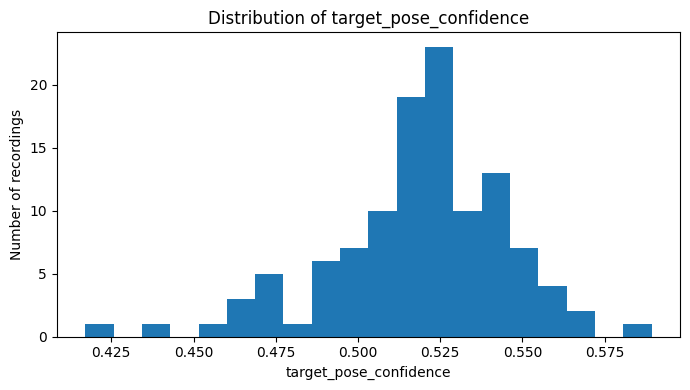

Saved: reporting\results\a14_distribution_target_pose_confidence.png


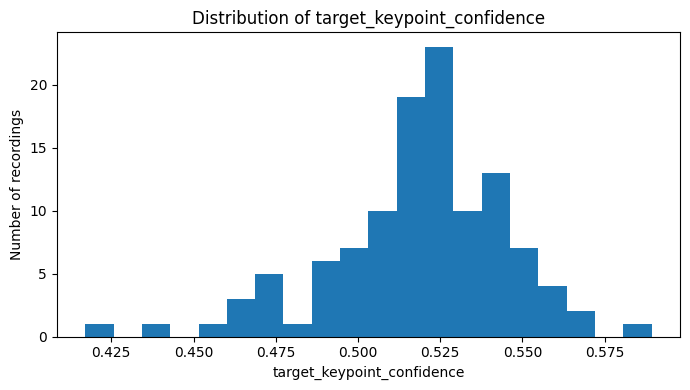

Saved: reporting\results\a14_distribution_target_keypoint_confidence.png


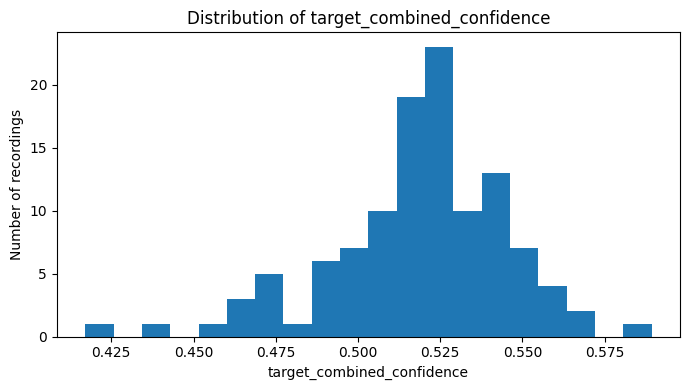

Saved: reporting\results\a14_distribution_target_combined_confidence.png


In [6]:
for col in [
    "target_pose_confidence",
    "target_keypoint_confidence",
    "target_combined_confidence",
]:
    plt.figure(figsize=(7, 4))
    plt.hist(kept_catalog_df[col], bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of recordings")
    plt.tight_layout()

    plot_path = output_dir / f"a14_distribution_{col}.png"
    plt.savefig(plot_path, dpi=150)
    plt.show()

    print("Saved:", plot_path)

## Feature preparation

The model uses only the first `c = 10` frames.

Supported feature sets:

1. `scores_only`
   - pose confidence + keypoint confidence scores

2. `coords_scores`
   - x/y coordinates + pose confidence + keypoint confidence scores

For each frame:

- `pose_score`: 1 feature
- `keypoint_scores`: 13 features
- `coords`: 26 features

So for `c = 10`:

- `scores_only`: `(1 + 13) * 10 = 140` features
- `coords_scores`: `(26 + 1 + 13) * 10 = 400` features

In [7]:
POSE_SCORE_COLS = ["pose_score"]


def take_first_frames(df: pd.DataFrame, seq_len: int) -> pd.DataFrame:
    if len(df) < seq_len:
        raise ValueError(f"Sequence has {len(df)} frames, but seq_len={seq_len}.")

    return df.iloc[:seq_len].copy().reset_index(drop=True)


def get_feature_columns(feature_set: str) -> list[str]:
    if feature_set == "scores_only":
        return POSE_SCORE_COLS + SCORE_COLS

    if feature_set == "coords_scores":
        return COORD_COLS + POSE_SCORE_COLS + SCORE_COLS

    raise ValueError(f"Unknown feature_set: {feature_set}")


def fit_feature_scaler(
    sequence_ids: list[str],
    sequence_dfs: dict[str, pd.DataFrame],
    feature_cols: list[str],
    seq_len: int,
) -> MinMaxScaler:
    rows = []

    for sequence_id in sequence_ids:
        df = sequence_dfs[sequence_id]
        first_df = take_first_frames(df, seq_len)
        rows.append(first_df[feature_cols])

    train_feature_df = pd.concat(rows, ignore_index=True)

    scaler = MinMaxScaler()
    scaler.fit(train_feature_df)

    return scaler


def sequence_to_matrix(
    df: pd.DataFrame,
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
) -> np.ndarray:
    feature_cols = get_feature_columns(feature_set)

    first_df = take_first_frames(df, seq_len)
    values_df = first_df[feature_cols].copy()

    values = scaler.transform(values_df)
    return values.astype(np.float32)


def sequence_to_dense_vector(
    df: pd.DataFrame,
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
) -> np.ndarray:
    matrix = sequence_to_matrix(
        df=df,
        scaler=scaler,
        seq_len=seq_len,
        feature_set=feature_set,
    )

    return matrix.reshape(-1)


def get_target_array(
    sequence_ids: list[str],
    labels_lookup: dict[str, dict[str, float]],
) -> np.ndarray:
    y_rows = []

    for sequence_id in sequence_ids:
        target_dict = labels_lookup[sequence_id]

        y_rows.append([
            target_dict["target_pose_confidence"],
            target_dict["target_keypoint_confidence"],
            target_dict["target_combined_confidence"],
        ])

    return np.array(y_rows, dtype=np.float32)


def build_xy_for_sequence_ids(
    sequence_ids: list[str],
    sequence_dfs: dict[str, pd.DataFrame],
    labels_lookup: dict[str, dict[str, float]],
    scaler: MinMaxScaler,
    seq_len: int,
    feature_set: str,
    model_family: str,
) -> tuple[np.ndarray, np.ndarray, list[str]]:
    X_rows = []
    ids = []

    for sequence_id in sequence_ids:
        df = sequence_dfs[sequence_id]

        if model_family == "Dense":
            x = sequence_to_dense_vector(
                df=df,
                scaler=scaler,
                seq_len=seq_len,
                feature_set=feature_set,
            )
        elif model_family in ["CNN", "LSTM"]:
            x = sequence_to_matrix(
                df=df,
                scaler=scaler,
                seq_len=seq_len,
                feature_set=feature_set,
            )
        else:
            raise ValueError(f"Unknown model_family: {model_family}")

        X_rows.append(x)
        ids.append(sequence_id)

    X = np.stack(X_rows).astype(np.float32)
    y = get_target_array(sequence_ids, labels_lookup)

    return X, y, ids

## Dataset, models, and training helpers

In [8]:
class ConfidenceDataset(Dataset):
    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class DenseCombinedConfidenceRegressor(nn.Module):
    """
    Small Dense model.

    Output:
    - pose confidence
    - keypoint confidence
    - combined confidence
    """
    def __init__(
        self,
        input_dim: int,
        hidden_dims: tuple[int, ...] = (32, 16),
        dropout: float = 0.05,
    ):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 3))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        raw = self.network(x)
        return torch.sigmoid(raw)


class CNNCombinedConfidenceRegressor(nn.Module):
    """
    Small 1D CNN over the first c frames.

    Input shape:
    batch, seq_len, n_features_per_frame
    """
    def __init__(
        self,
        n_features_per_frame: int,
        channels: tuple[int, ...] = (8, 8),
        kernel_size: int = 3,
        dense_dim: int = 16,
        dropout: float = 0.05,
    ):
        super().__init__()

        conv_layers = []
        prev_channels = n_features_per_frame

        for out_channels in channels:
            conv_layers.append(
                nn.Conv1d(
                    in_channels=prev_channels,
                    out_channels=out_channels,
                    kernel_size=kernel_size,
                    padding=kernel_size // 2,
                )
            )
            conv_layers.append(nn.ReLU())
            prev_channels = out_channels

        self.conv = nn.Sequential(*conv_layers)
        self.pool = nn.AdaptiveAvgPool1d(1)

        self.head = nn.Sequential(
            nn.Linear(prev_channels, dense_dim),
            nn.ReLU(),
            nn.Dropout(dropout) if dropout > 0 else nn.Identity(),
            nn.Linear(dense_dim, 3),
        )

    def forward(self, x):
        # x: batch, seq_len, features
        x = x.transpose(1, 2)  # batch, features, seq_len
        x = self.conv(x)
        x = self.pool(x).squeeze(-1)
        raw = self.head(x)
        return torch.sigmoid(raw)


class LSTMCombinedConfidenceRegressor(nn.Module):
    """
    Small LSTM over the first c frames.

    Input shape:
    batch, seq_len, n_features_per_frame
    """
    def __init__(
        self,
        n_features_per_frame: int,
        hidden_size: int = 16,
        num_layers: int = 1,
        dropout: float = 0.00,
    ):
        super().__init__()

        lstm_dropout = dropout if num_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size=n_features_per_frame,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
        )

        self.head = nn.Linear(hidden_size, 3)

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)
        last_hidden = h_n[-1]
        raw = self.head(last_hidden)
        return torch.sigmoid(raw)


def count_trainable_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def estimate_macs(config: dict, input_shape: tuple[int, ...]) -> int:
    """
    Approximate dynamically executed multiply-accumulate operations for one prediction.

    This is an approximation for reporting online decision capability.
    """
    model_family = config["model_family"]

    if model_family == "Dense":
        input_dim = input_shape[0]
        dims = [input_dim] + list(config["hidden_dims"]) + [3]
        return int(sum(dims[i] * dims[i + 1] for i in range(len(dims) - 1)))

    if model_family == "CNN":
        seq_len, n_features = input_shape
        channels = config["channels"]
        kernel_size = config["kernel_size"]

        macs = 0
        prev_channels = n_features

        for out_channels in channels:
            macs += seq_len * prev_channels * out_channels * kernel_size
            prev_channels = out_channels

        macs += prev_channels * config["dense_dim"]
        macs += config["dense_dim"] * 3
        return int(macs)

    if model_family == "LSTM":
        seq_len, n_features = input_shape
        hidden_size = config["hidden_size"]
        num_layers = config["num_layers"]

        # Approximate LSTM MACs:
        # 4 gates * (input_size * hidden + hidden * hidden) per time step
        macs = 0
        layer_input_size = n_features

        for _ in range(num_layers):
            macs += seq_len * 4 * (
                layer_input_size * hidden_size
                + hidden_size * hidden_size
            )
            layer_input_size = hidden_size

        macs += hidden_size * 3
        return int(macs)

    raise ValueError(f"Unknown model_family: {model_family}")


def make_model(config: dict, input_shape: tuple[int, ...]) -> nn.Module:
    model_family = config["model_family"]

    if model_family == "Dense":
        input_dim = input_shape[0]

        return DenseCombinedConfidenceRegressor(
            input_dim=input_dim,
            hidden_dims=config["hidden_dims"],
            dropout=config["dropout"],
        )

    if model_family == "CNN":
        seq_len, n_features = input_shape

        return CNNCombinedConfidenceRegressor(
            n_features_per_frame=n_features,
            channels=config["channels"],
            kernel_size=config["kernel_size"],
            dense_dim=config["dense_dim"],
            dropout=config["dropout"],
        )

    if model_family == "LSTM":
        seq_len, n_features = input_shape

        return LSTMCombinedConfidenceRegressor(
            n_features_per_frame=n_features,
            hidden_size=config["hidden_size"],
            num_layers=config["num_layers"],
            dropout=config["dropout"],
        )

    raise ValueError(f"Unknown model_family: {model_family}")


def make_loader(
    X: np.ndarray,
    y: np.ndarray,
    batch_size: int,
    shuffle: bool,
) -> DataLoader:
    dataset = ConfidenceDataset(X, y)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
    )

## Evaluation and training helpers

In [9]:
TARGET_NAMES = [
    "pose_confidence",
    "keypoint_confidence",
    "combined_confidence",
]


def evaluate_regression_model(
    model: nn.Module,
    loader: DataLoader,
) -> dict:
    model.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)

            preds = model(X_batch).detach().cpu().numpy()

            all_pred.append(preds)
            all_true.append(y_batch.numpy())

    y_true = np.vstack(all_true)
    y_pred = np.vstack(all_pred)

    metrics = {}

    for idx, name in enumerate(TARGET_NAMES):
        true_col = y_true[:, idx]
        pred_col = y_pred[:, idx]

        mae = mean_absolute_error(true_col, pred_col)
        mse = mean_squared_error(true_col, pred_col)
        rmse = float(np.sqrt(mse))

        try:
            r2 = r2_score(true_col, pred_col)
        except Exception:
            r2 = np.nan

        metrics[f"{name}_mae"] = float(mae)
        metrics[f"{name}_mse"] = float(mse)
        metrics[f"{name}_rmse"] = float(rmse)
        metrics[f"{name}_r2"] = float(r2)

    metrics["mean_mae_all_targets"] = float(
        np.mean([
            metrics["pose_confidence_mae"],
            metrics["keypoint_confidence_mae"],
            metrics["combined_confidence_mae"],
        ])
    )

    metrics["y_true"] = y_true
    metrics["y_pred"] = y_pred

    return metrics


def train_one_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    learning_rate: float,
    epochs: int,
    patience: int,
):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    best_state = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf
    best_epoch = 0
    epochs_without_improvement = 0

    history_rows = []

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            preds = model(X_batch)
            loss = criterion(preds, y_batch)

            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        model.eval()
        val_losses = []

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                preds = model(X_batch)
                loss = criterion(preds, y_batch)

                val_losses.append(loss.item())

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))

        history_rows.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)

    history_df = pd.DataFrame(history_rows)

    summary = {
        "best_val_loss": float(best_val_loss),
        "best_epoch": int(best_epoch),
        "epochs_ran": int(len(history_df)),
    }

    return model, history_df, summary

## Prepare IDs, labels, and cross-validation folds

In [10]:
sequence_ids_all = kept_catalog_df["sequence_id"].tolist()

labels_lookup = {}

for _, row in kept_catalog_df.iterrows():
    labels_lookup[row["sequence_id"]] = {
        "target_pose_confidence": float(row["target_pose_confidence"]),
        "target_keypoint_confidence": float(row["target_keypoint_confidence"]),
        "target_combined_confidence": float(row["target_combined_confidence"]),
    }

n_splits = min(N_SPLITS, len(sequence_ids_all))

if n_splits < 2:
    raise RuntimeError("Need at least two kept recordings for train/test evaluation.")

cv_splitter = KFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=RANDOM_SEED,
)

cv_splits = list(cv_splitter.split(sequence_ids_all))

print("Number of kept recordings:", len(sequence_ids_all))
print("Number of CV folds:", len(cv_splits))

Number of kept recordings: 114
Number of CV folds: 10


## Cross-validation experiment function

In [11]:
def make_train_val_split(
    train_val_sequence_ids: list[str],
    validation_split: float,
    random_state: int,
) -> tuple[list[str], list[str]]:
    train_ids, val_ids = train_test_split(
        train_val_sequence_ids,
        test_size=validation_split,
        random_state=random_state,
    )

    return list(train_ids), list(val_ids)


def run_cv_experiment(
    config: dict,
    run_name: str,
    log_to_mlflow: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    fold_rows = []
    history_rows = []

    with mlflow.start_run(run_name=run_name) if log_to_mlflow else nullcontext():
        feature_cols = get_feature_columns(config["feature_set"])

        if log_to_mlflow:
            mlflow.log_param("task", "combined_pose_keypoint_ugly_recording_regression")
            mlflow.log_param("input_type", "MoveNet_pose_and_keypoint_confidence")
            mlflow.log_param("model_family", config["model_family"])
            mlflow.log_param("target", "pose_keypoint_combined_confidence")
            mlflow.log_param("seq_len", config["seq_len"])
            mlflow.log_param("feature_set", config["feature_set"])
            mlflow.log_param("batch_size", config["batch_size"])
            mlflow.log_param("learning_rate", config["learning_rate"])
            mlflow.log_param("epochs", config["epochs"])
            mlflow.log_param("patience", config["patience"])
            mlflow.log_param("n_recordings", len(sequence_ids_all))
            mlflow.log_param("online_decision", True)
            mlflow.log_param("uses_only_first_frames", True)

            for key, value in config.items():
                if key not in [
                    "seq_len",
                    "feature_set",
                    "batch_size",
                    "learning_rate",
                    "epochs",
                    "patience",
                ]:
                    mlflow.log_param(key, str(value))

        for fold_idx, (train_val_idx, test_idx) in enumerate(cv_splits, start=1):
            train_val_ids = [sequence_ids_all[i] for i in train_val_idx]
            test_ids = [sequence_ids_all[i] for i in test_idx]

            train_ids, val_ids = make_train_val_split(
                train_val_sequence_ids=train_val_ids,
                validation_split=VALIDATION_SPLIT,
                random_state=RANDOM_SEED + fold_idx,
            )

            scaler = fit_feature_scaler(
                sequence_ids=train_ids,
                sequence_dfs=sequence_dfs,
                feature_cols=feature_cols,
                seq_len=config["seq_len"],
            )

            X_train, y_train, _ = build_xy_for_sequence_ids(
                sequence_ids=train_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
                model_family=config["model_family"],
            )

            X_val, y_val, _ = build_xy_for_sequence_ids(
                sequence_ids=val_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
                model_family=config["model_family"],
            )

            X_test, y_test, test_ids_used = build_xy_for_sequence_ids(
                sequence_ids=test_ids,
                sequence_dfs=sequence_dfs,
                labels_lookup=labels_lookup,
                scaler=scaler,
                seq_len=config["seq_len"],
                feature_set=config["feature_set"],
                model_family=config["model_family"],
            )

            input_shape = X_train.shape[1:]

            model = make_model(
                config=config,
                input_shape=input_shape,
            ).to(DEVICE)

            n_parameters = count_trainable_parameters(model)
            estimated_macs = estimate_macs(config, input_shape)

            train_loader = make_loader(
                X_train,
                y_train,
                batch_size=config["batch_size"],
                shuffle=True,
            )

            val_loader = make_loader(
                X_val,
                y_val,
                batch_size=config["batch_size"],
                shuffle=False,
            )

            test_loader = make_loader(
                X_test,
                y_test,
                batch_size=config["batch_size"],
                shuffle=False,
            )

            start_time = time.perf_counter()

            model, history_df, train_summary = train_one_model(
                model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                learning_rate=config["learning_rate"],
                epochs=config["epochs"],
                patience=config["patience"],
            )

            train_time_seconds = time.perf_counter() - start_time

            train_metrics = evaluate_regression_model(model, train_loader)
            val_metrics = evaluate_regression_model(model, val_loader)
            test_metrics = evaluate_regression_model(model, test_loader)

            model.eval()

            with torch.no_grad():
                example_x = torch.tensor(X_test[:1], dtype=torch.float32).to(DEVICE)

                timing_repeats = 200
                t0 = time.perf_counter()

                for _ in range(timing_repeats):
                    _ = model(example_x)

                t1 = time.perf_counter()

            mean_prediction_ms = ((t1 - t0) / timing_repeats) * 1000.0

            fold_row = {
                "run_name": run_name,
                "fold": fold_idx,
                "model_family": config["model_family"],
                "feature_set": config["feature_set"],
                "config_name": config["name"],
                "seq_len": config["seq_len"],
                "input_shape": str(input_shape),
                "n_parameters": n_parameters,
                "estimated_macs_per_prediction": estimated_macs,
                "mean_prediction_ms": mean_prediction_ms,
                "n_train": len(train_ids),
                "n_val": len(val_ids),
                "n_test": len(test_ids),
                "best_val_loss": train_summary["best_val_loss"],
                "best_epoch": train_summary["best_epoch"],
                "epochs_ran": train_summary["epochs_ran"],
                "train_time_seconds": train_time_seconds,
            }

            for prefix, metrics in [
                ("train", train_metrics),
                ("val", val_metrics),
                ("test", test_metrics),
            ]:
                for key, value in metrics.items():
                    if key not in ["y_true", "y_pred"]:
                        fold_row[f"{prefix}_{key}"] = value

            fold_rows.append(fold_row)

            fold_history = history_df.copy()
            fold_history["run_name"] = run_name
            fold_history["fold"] = fold_idx
            history_rows.append(fold_history)

            if log_to_mlflow:
                for key, value in fold_row.items():
                    if isinstance(value, (int, float, np.integer, np.floating)):
                        mlflow.log_metric(f"fold_{fold_idx}_{key}", float(value))

        fold_df = pd.DataFrame(fold_rows)
        history_df = pd.concat(history_rows, ignore_index=True)

        if log_to_mlflow:
            numeric_summary = fold_df.select_dtypes(include=[np.number]).mean().to_dict()

            for key, value in numeric_summary.items():
                mlflow.log_metric(f"mean_{key}", float(value))

    return fold_df, history_df

## Hyperparameter search

The variants are intentionally small because the model should support online decisions.

We compare:

- Dense
- CNN
- LSTM

The champion is chosen mainly by low combined-confidence MAE, but model size and operations are also considered.

In [12]:
COMBINED_CONFIGS = [
    {
        "name": "dense_scores_16_8",
        "model_family": "Dense",
        "seq_len": SEQ_LEN,
        "feature_set": "scores_only",
        "hidden_dims": (16, 8),
        "dropout": 0.05,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "dense_scores_32_16",
        "model_family": "Dense",
        "seq_len": SEQ_LEN,
        "feature_set": "scores_only",
        "hidden_dims": (32, 16),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "dense_coords_scores_32_16",
        "model_family": "Dense",
        "seq_len": SEQ_LEN,
        "feature_set": "coords_scores",
        "hidden_dims": (32, 16),
        "dropout": 0.10,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "cnn_scores_8_8",
        "model_family": "CNN",
        "seq_len": SEQ_LEN,
        "feature_set": "scores_only",
        "channels": (8, 8),
        "kernel_size": 3,
        "dense_dim": 16,
        "dropout": 0.05,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "cnn_coords_scores_8_8",
        "model_family": "CNN",
        "seq_len": SEQ_LEN,
        "feature_set": "coords_scores",
        "channels": (8, 8),
        "kernel_size": 3,
        "dense_dim": 16,
        "dropout": 0.05,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "lstm_scores_16",
        "model_family": "LSTM",
        "seq_len": SEQ_LEN,
        "feature_set": "scores_only",
        "hidden_size": 16,
        "num_layers": 1,
        "dropout": 0.00,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
    {
        "name": "lstm_coords_scores_16",
        "model_family": "LSTM",
        "seq_len": SEQ_LEN,
        "feature_set": "coords_scores",
        "hidden_size": 16,
        "num_layers": 1,
        "dropout": 0.00,
        "batch_size": 16,
        "learning_rate": 1e-3,
        "epochs": EPOCHS,
        "patience": PATIENCE,
    },
]

In [13]:
all_search_folds = []
all_search_histories = []

for config in COMBINED_CONFIGS:
    run_name = f"a14_combined_{config['name']}"

    fold_df, history_df = run_cv_experiment(
        config=config,
        run_name=run_name,
        log_to_mlflow=True,
    )

    all_search_folds.append(fold_df)
    all_search_histories.append(history_df)

search_results_df = pd.concat(all_search_folds, ignore_index=True)
search_history_df = pd.concat(all_search_histories, ignore_index=True)

search_results_path = output_dir / "a14_combined_pose_keypoint_hyperparameter_search_folds.csv"
search_history_path = output_dir / "a14_combined_pose_keypoint_hyperparameter_search_history.csv"

search_results_df.to_csv(search_results_path, index=False)
search_history_df.to_csv(search_history_path, index=False)

display(search_results_df.head())

print("Saved:", search_results_path)
print("Saved:", search_history_path)

🏃 View run a14_combined_dense_scores_16_8 at: https://172.27.62.170:5001/#/experiments/35/runs/bf149edb198e408e8bf2b4b15c2ae436
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/35
🏃 View run a14_combined_dense_scores_32_16 at: https://172.27.62.170:5001/#/experiments/35/runs/b9d4c8412f3f40778c92810e1ffa342a
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/35
🏃 View run a14_combined_dense_coords_scores_32_16 at: https://172.27.62.170:5001/#/experiments/35/runs/19b6691ab4fe4d31af66fe69aba67b6a
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/35
🏃 View run a14_combined_cnn_scores_8_8 at: https://172.27.62.170:5001/#/experiments/35/runs/2b892edf81d04c50a5a83579b4c841c3
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/35
🏃 View run a14_combined_cnn_coords_scores_8_8 at: https://172.27.62.170:5001/#/experiments/35/runs/917e9990db914f4cb7df2930b78ec385
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/35
🏃 View run a14_combi

,run_name,fold,model_family,feature_set,config_name,seq_len,input_shape,n_parameters,estimated_macs_per_prediction,mean_prediction_ms,...,test_pose_confidence_r2,test_keypoint_confidence_mae,test_keypoint_confidence_mse,test_keypoint_confidence_rmse,test_keypoint_confidence_r2,test_combined_confidence_mae,test_combined_confidence_mse,test_combined_confidence_rmse,test_combined_confidence_r2,test_mean_mae_all_targets
0,a14_combined_dense_scores_16_8,1,Dense,scores_only,dense_scores_16_8,10,"(140,)",2419,2392,0.289173,...,0.688839,0.018555,0.000659,0.025680,-0.201830,0.010302,0.000226,0.015025,0.588571,0.012971
1,a14_combined_dense_scores_16_8,2,Dense,scores_only,dense_scores_16_8,10,"(140,)",2419,2392,0.232058,...,0.117808,0.021615,0.000774,0.027813,0.041781,0.022086,0.000735,0.027118,0.089044,0.021622
2,a14_combined_dense_scores_16_8,3,Dense,scores_only,dense_scores_16_8,10,"(140,)",2419,2392,0.272265,...,0.322340,0.018985,0.000490,0.022142,0.499230,0.021315,0.000722,0.026865,0.262825,0.020242
3,a14_combined_dense_scores_16_8,4,Dense,scores_only,dense_scores_16_8,10,"(140,)",2419,2392,0.220461,...,-0.119210,0.016362,0.000561,0.023677,-0.303826,0.013651,0.000480,0.021899,-0.115308,0.014930
4,a14_combined_dense_scores_16_8,5,Dense,scores_only,dense_scores_16_8,10,"(140,)",2419,2392,0.237278,...,-0.222356,0.018944,0.000478,0.021864,-0.241060,0.018063,0.000458,0.021408,-0.189798,0.018457


Saved: reporting\results\a14_combined_pose_keypoint_hyperparameter_search_folds.csv
Saved: reporting\results\a14_combined_pose_keypoint_hyperparameter_search_history.csv


## Summarize hyperparameter search

In [14]:
summary_df = (
    search_results_df
    .groupby(
        [
            "run_name",
            "config_name",
            "model_family",
            "feature_set",
            "seq_len",
            "input_shape",
        ],
        as_index=False,
    )
    .agg(
        n_parameters=("n_parameters", "mean"),
        estimated_macs_per_prediction=("estimated_macs_per_prediction", "mean"),
        mean_prediction_ms=("mean_prediction_ms", "mean"),
        mean_test_pose_mae=("test_pose_confidence_mae", "mean"),
        std_test_pose_mae=("test_pose_confidence_mae", "std"),
        mean_test_keypoint_mae=("test_keypoint_confidence_mae", "mean"),
        std_test_keypoint_mae=("test_keypoint_confidence_mae", "std"),
        mean_test_combined_mae=("test_combined_confidence_mae", "mean"),
        std_test_combined_mae=("test_combined_confidence_mae", "std"),
        mean_test_all_targets_mae=("test_mean_mae_all_targets", "mean"),
        std_test_all_targets_mae=("test_mean_mae_all_targets", "std"),
        mean_test_combined_r2=("test_combined_confidence_r2", "mean"),
        std_test_combined_r2=("test_combined_confidence_r2", "std"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_epochs_ran=("epochs_ran", "mean"),
    )
    .sort_values(
        [
            "mean_test_combined_mae",
            "mean_test_all_targets_mae",
            "n_parameters",
        ],
        ascending=[True, True, True],
    )
)

summary_path = output_dir / "a14_combined_pose_keypoint_hyperparameter_search_summary.csv"
summary_df.to_csv(summary_path, index=False)

display(summary_df)

print("Saved:", summary_path)

,run_name,config_name,model_family,feature_set,seq_len,input_shape,n_parameters,estimated_macs_per_prediction,mean_prediction_ms,mean_test_pose_mae,...,mean_test_keypoint_mae,std_test_keypoint_mae,mean_test_combined_mae,std_test_combined_mae,mean_test_all_targets_mae,std_test_all_targets_mae,mean_test_combined_r2,std_test_combined_r2,mean_best_epoch,mean_epochs_ran
3,a14_combined_dense_scores_16_8,dense_scores_16_8,Dense,scores_only,10,"(140,)",2419.0,2392.0,0.246631,0.017625,...,0.018906,0.003511,0.018042,0.005172,0.018191,0.004252,0.079405,0.337272,63.4,76.7
4,a14_combined_dense_scores_32_16,dense_scores_32_16,Dense,scores_only,10,"(140,)",5091.0,5040.0,0.244747,0.018299,...,0.018061,0.003705,0.018534,0.002915,0.018298,0.003218,-0.022288,0.404791,54.3,67.9
1,a14_combined_cnn_scores_8_8,cnn_scores_8_8,CNN,scores_only,10,"(10, 14)",739.0,5456.0,0.425029,0.019329,...,0.018968,0.005930,0.018716,0.006052,0.019004,0.006126,0.015621,0.299470,48.2,62.0
0,a14_combined_cnn_coords_scores_8_8,cnn_coords_scores_8_8,CNN,coords_scores,10,"(10, 40)",1363.0,11696.0,0.386417,0.018499,...,0.018407,0.005248,0.018716,0.005463,0.018541,0.005217,-0.086647,0.458756,45.6,60.3
2,a14_combined_dense_coords_scores_32_16,dense_coords_scores_32_16,Dense,coords_scores,10,"(400,)",13411.0,13360.0,0.255664,0.019120,...,0.019212,0.004275,0.019085,0.004114,0.019139,0.003955,-0.119207,0.491713,32.4,47.4
6,a14_combined_lstm_scores_16,lstm_scores_16,LSTM,scores_only,10,"(10, 14)",2099.0,19248.0,0.273992,0.019670,...,0.019406,0.004369,0.019394,0.004005,0.019490,0.004235,-0.069145,0.331758,35.9,49.6
5,a14_combined_lstm_coords_scores_16,lstm_coords_scores_16,LSTM,coords_scores,10,"(10, 40)",3763.0,35888.0,0.274593,0.018911,...,0.018084,0.004367,0.019725,0.005346,0.018907,0.004512,-0.230502,0.567711,27.0,42.0


Saved: reporting\results\a14_combined_pose_keypoint_hyperparameter_search_summary.csv


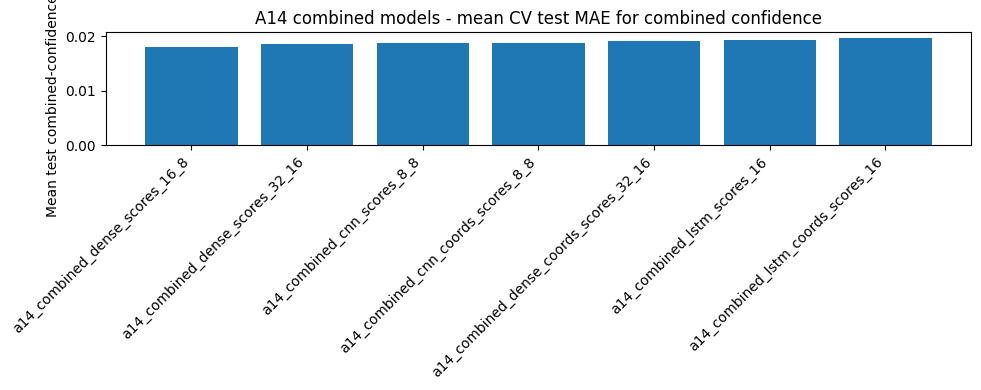

Saved: reporting\results\a14_combined_model_mae_comparison.png


In [15]:
plt.figure(figsize=(10, 4))
plt.bar(summary_df["run_name"], summary_df["mean_test_combined_mae"])
plt.title("A14 combined models - mean CV test MAE for combined confidence")
plt.ylabel("Mean test combined-confidence MAE")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

mae_plot_path = output_dir / "a14_combined_model_mae_comparison.png"
plt.savefig(mae_plot_path, dpi=150)
plt.show()

print("Saved:", mae_plot_path)

## Select champion

The champion is selected by:

1. Lowest mean test MAE for the combined confidence score.
2. If close, prefer lower mean MAE across all targets.
3. If close, prefer fewer parameters and fewer operations.

In [16]:
best_run_name = summary_df.iloc[0]["run_name"]
best_config_name = summary_df.iloc[0]["config_name"]

CHAMPION_CONFIG = None

for config in COMBINED_CONFIGS:
    if config["name"] == best_config_name:
        CHAMPION_CONFIG = config.copy()
        break

if CHAMPION_CONFIG is None:
    raise RuntimeError("Could not find champion config.")

print("Best run:", best_run_name)
print("Selected champion config:")
print(json.dumps(CHAMPION_CONFIG, indent=2))

Best run: a14_combined_dense_scores_16_8
Selected champion config:
{
  "name": "dense_scores_16_8",
  "model_family": "Dense",
  "seq_len": 10,
  "feature_set": "scores_only",
  "hidden_dims": [
    16,
    8
  ],
  "dropout": 0.05,
  "batch_size": 16,
  "learning_rate": 0.001,
  "epochs": 120,
  "patience": 15
}


## Train final champion on all available data

In [17]:
def train_final_model_on_all_sequences(config: dict):
    all_ids = sequence_ids_all.copy()

    train_ids, val_ids = train_test_split(
        all_ids,
        test_size=VALIDATION_SPLIT,
        random_state=RANDOM_SEED,
    )

    feature_cols = get_feature_columns(config["feature_set"])

    final_scaler = fit_feature_scaler(
        sequence_ids=train_ids,
        sequence_dfs=sequence_dfs,
        feature_cols=feature_cols,
        seq_len=config["seq_len"],
    )

    X_train, y_train, train_ids_used = build_xy_for_sequence_ids(
        sequence_ids=train_ids,
        sequence_dfs=sequence_dfs,
        labels_lookup=labels_lookup,
        scaler=final_scaler,
        seq_len=config["seq_len"],
        feature_set=config["feature_set"],
        model_family=config["model_family"],
    )

    X_val, y_val, val_ids_used = build_xy_for_sequence_ids(
        sequence_ids=val_ids,
        sequence_dfs=sequence_dfs,
        labels_lookup=labels_lookup,
        scaler=final_scaler,
        seq_len=config["seq_len"],
        feature_set=config["feature_set"],
        model_family=config["model_family"],
    )

    input_shape = X_train.shape[1:]

    final_model = make_model(
        config=config,
        input_shape=input_shape,
    ).to(DEVICE)

    train_loader = make_loader(
        X_train,
        y_train,
        batch_size=config["batch_size"],
        shuffle=True,
    )

    val_loader = make_loader(
        X_val,
        y_val,
        batch_size=config["batch_size"],
        shuffle=False,
    )

    final_model, final_history_df, final_train_summary = train_one_model(
        model=final_model,
        train_loader=train_loader,
        val_loader=val_loader,
        learning_rate=config["learning_rate"],
        epochs=config["epochs"],
        patience=config["patience"],
    )

    train_metrics = evaluate_regression_model(final_model, train_loader)
    val_metrics = evaluate_regression_model(final_model, val_loader)

    final_info = {
        "input_shape": str(input_shape),
        "n_parameters": count_trainable_parameters(final_model),
        "estimated_macs_per_prediction": estimate_macs(config, input_shape),
        "n_train_sequences": len(train_ids),
        "n_val_sequences": len(val_ids),
        "best_val_loss": final_train_summary["best_val_loss"],
        "best_epoch": final_train_summary["best_epoch"],
        "epochs_ran": final_train_summary["epochs_ran"],
    }

    for prefix, metrics in [
        ("train", train_metrics),
        ("val", val_metrics),
    ]:
        for key, value in metrics.items():
            if key not in ["y_true", "y_pred"]:
                final_info[f"{prefix}_{key}"] = value

    return final_model, final_scaler, final_history_df, final_info


final_model, final_scaler, final_history_df, final_info = train_final_model_on_all_sequences(CHAMPION_CONFIG)

print("Final champion info:")
print(json.dumps(final_info, indent=2))

Final champion info:
{
  "input_shape": "(140,)",
  "n_parameters": 2419,
  "estimated_macs_per_prediction": 2392,
  "n_train_sequences": 102,
  "n_val_sequences": 12,
  "best_val_loss": 0.00023886204871814698,
  "best_epoch": 50,
  "epochs_ran": 65,
  "train_pose_confidence_mae": 0.016285523772239685,
  "train_pose_confidence_mse": 0.00040934549178928137,
  "train_pose_confidence_rmse": 0.020232288166880608,
  "train_pose_confidence_r2": 0.460829496383667,
  "train_keypoint_confidence_mae": 0.01627242937684059,
  "train_keypoint_confidence_mse": 0.00042078131809830666,
  "train_keypoint_confidence_rmse": 0.020512955263257027,
  "train_keypoint_confidence_r2": 0.44576650857925415,
  "train_combined_confidence_mae": 0.01632133685052395,
  "train_combined_confidence_mse": 0.00042993301758542657,
  "train_combined_confidence_rmse": 0.02073482610285282,
  "train_combined_confidence_r2": 0.433712363243103,
  "train_mean_mae_all_targets": 0.01629309666653474,
  "val_pose_confidence_mae": 0.0

## MLflow pyfunc wrapper

The wrapper makes the final model reusable.

It accepts raw MoveNet data and performs:

1. MoveNet-to-assignment conversion
2. pose/keypoint score extraction
3. first-frame selection
4. feature scaling
5. Dense/CNN/LSTM prediction
6. combined accept/warn/reject decision

In [18]:
class CombinedPoseKeypointConfidencePredictor(mlflow.pyfunc.PythonModel):
    """
    MLflow pyfunc wrapper for A14 combined pose + keypoint confidence prediction.

    Expected input to predict():
    - pandas DataFrame with one or more MoveNet sequences
    - If multiple sequences are included, a sequence_id column should be present
    - If sequence_id is missing, the whole input is treated as one sequence

    Output:
    - predicted pose confidence
    - predicted keypoint confidence
    - predicted combined confidence
    - practical decision: accept/warn/reject
    """

    def __init__(
        self,
        model,
        scaler,
        champion_config,
        coord_cols,
        score_cols,
        joints_13,
        movenet_to_assignment,
        pose_score_candidates,
        accept_threshold=0.70,
        warn_threshold=0.60,
        pose_weight=0.50,
        keypoint_weight=0.50,
        device="cpu",
    ):
        self.model = model
        self.scaler = scaler
        self.champion_config = champion_config
        self.coord_cols = coord_cols
        self.score_cols = score_cols
        self.joints_13 = joints_13
        self.movenet_to_assignment = movenet_to_assignment
        self.pose_score_candidates = pose_score_candidates
        self.accept_threshold = accept_threshold
        self.warn_threshold = warn_threshold
        self.pose_weight = pose_weight
        self.keypoint_weight = keypoint_weight
        self.device = device

    def _strip_columns(self, df):
        df = df.copy()
        df.columns = [str(c).strip() for c in df.columns]
        return df

    def _find_frame_col(self, df):
        for col in FRAME_COL_CANDIDATES:
            if col in df.columns:
                return col

        raise ValueError(
            f"Could not find a frame column. Available columns: {df.columns.tolist()}"
        )

    def _find_pose_score_col(self, df):
        for col in self.pose_score_candidates:
            if col in df.columns:
                return col

        return None

    def _movenet_as_assignment(self, df):
        df = self._strip_columns(df)

        required_assignment_cols = set(self.coord_cols + self.score_cols)

        if required_assignment_cols.issubset(set(df.columns)):
            out = df.copy()

            if "frame_index" not in out.columns:
                frame_col = self._find_frame_col(out)
                out["frame_index"] = pd.to_numeric(out[frame_col], errors="coerce").astype(int)

            pose_col = self._find_pose_score_col(out)

            if pose_col is not None:
                out["pose_score"] = pd.to_numeric(out[pose_col], errors="coerce")
            elif "pose_score" not in out.columns:
                out["pose_score"] = out[self.score_cols].mean(axis=1)

            return out.sort_values("frame_index").reset_index(drop=True)

        frame_col = self._find_frame_col(df)
        pose_col = self._find_pose_score_col(df)

        out = pd.DataFrame()
        out["frame_index"] = pd.to_numeric(df[frame_col], errors="coerce").astype(int)

        for movenet_joint, assignment_joint in self.movenet_to_assignment.items():
            for suffix in ["x", "y", "score"]:
                src = f"{movenet_joint}_{suffix}"
                dst = f"{assignment_joint}_{suffix}"

                if src in df.columns:
                    out[dst] = pd.to_numeric(df[src], errors="coerce")
                elif dst in df.columns:
                    out[dst] = pd.to_numeric(df[dst], errors="coerce")
                else:
                    raise ValueError(f"Missing required column: {src} or {dst}")

        if pose_col is not None:
            out["pose_score"] = pd.to_numeric(df[pose_col], errors="coerce")
        else:
            out["pose_score"] = out[self.score_cols].mean(axis=1)

        return out.sort_values("frame_index").reset_index(drop=True)

    def _get_feature_columns(self):
        feature_set = self.champion_config["feature_set"]

        if feature_set == "scores_only":
            return ["pose_score"] + self.score_cols

        if feature_set == "coords_scores":
            return self.coord_cols + ["pose_score"] + self.score_cols

        raise ValueError(f"Unknown feature_set: {feature_set}")

    def _sequence_to_model_input(self, df):
        seq_len = self.champion_config["seq_len"]
        model_family = self.champion_config["model_family"]
        feature_cols = self._get_feature_columns()

        if len(df) < seq_len:
            raise ValueError(
                f"Sequence has {len(df)} frames, but model requires at least {seq_len} frames."
            )

        first_df = df.iloc[:seq_len].copy().reset_index(drop=True)
        values_df = first_df[feature_cols].copy()

        values = self.scaler.transform(values_df).astype(np.float32)

        if model_family == "Dense":
            return values.reshape(1, -1)

        if model_family in ["CNN", "LSTM"]:
            return values.reshape(1, seq_len, len(feature_cols))

        raise ValueError(f"Unknown model_family: {model_family}")

    def _decision_from_score(self, score):
        if score >= self.accept_threshold:
            return "accept"

        if score >= self.warn_threshold:
            return "warn"

        return "reject"

    def predict(self, context, model_input):
        df = model_input.copy()

        if "sequence_id" not in df.columns:
            df["sequence_id"] = "sequence_0"

        rows = []

        self.model.eval()
        self.model.to(self.device)

        for sequence_id, group_df in df.groupby("sequence_id"):
            seq_df = self._movenet_as_assignment(group_df)
            x = self._sequence_to_model_input(seq_df)

            x_tensor = torch.tensor(x, dtype=torch.float32).to(self.device)

            with torch.no_grad():
                pred = self.model(x_tensor).detach().cpu().numpy()[0]

            pred_pose = float(pred[0])
            pred_keypoint = float(pred[1])
            pred_combined = float(pred[2])

            # Recalculate the final combined score from predicted pose and keypoint.
            # This makes the output transparent and consistent with the selected weights.
            weighted_combined = (
                self.pose_weight * pred_pose
                + self.keypoint_weight * pred_keypoint
            )

            rows.append({
                "sequence_id": sequence_id,
                "predicted_pose_confidence": pred_pose,
                "predicted_keypoint_confidence": pred_keypoint,
                "predicted_combined_confidence": pred_combined,
                "weighted_combined_confidence": weighted_combined,
                "decision": self._decision_from_score(weighted_combined),
                "accept_threshold": self.accept_threshold,
                "warn_threshold": self.warn_threshold,
            })

        return pd.DataFrame(rows)


final_wrapped_combined_model = CombinedPoseKeypointConfidencePredictor(
    model=final_model.cpu(),
    scaler=final_scaler,
    champion_config=CHAMPION_CONFIG,
    coord_cols=COORD_COLS,
    score_cols=SCORE_COLS,
    joints_13=JOINTS_13,
    movenet_to_assignment=MOVENET_TO_ASSIGNMENT,
    pose_score_candidates=POSE_SCORE_CANDIDATES,
    accept_threshold=ACCEPT_THRESHOLD,
    warn_threshold=WARN_THRESHOLD,
    pose_weight=POSE_WEIGHT,
    keypoint_weight=KEYPOINT_WEIGHT,
    device="cpu",
)

c:\Users\Kim\software engineering\year 4\LP3\4DT907\machine_learning_project_4dt907\.venv\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


## Save and log final model to MLflow

In [19]:
final_model_path = artifact_dir / "a14_combined_pose_keypoint_champion_model.pt"
final_scaler_path = artifact_dir / "a14_combined_pose_keypoint_scaler.joblib"
final_config_path = artifact_dir / "a14_combined_pose_keypoint_champion_config.json"
final_history_path = output_dir / "a14_combined_pose_keypoint_champion_training_history.csv"

torch.save(final_model.cpu().state_dict(), final_model_path)
joblib.dump(final_scaler, final_scaler_path)
final_history_df.to_csv(final_history_path, index=False)

final_config_to_save = {
    **CHAMPION_CONFIG,
    "final_info": final_info,
    "coord_cols": COORD_COLS,
    "score_cols": SCORE_COLS,
    "joints_13": JOINTS_13,
    "target_names": TARGET_NAMES,
    "pose_weight": POSE_WEIGHT,
    "keypoint_weight": KEYPOINT_WEIGHT,
    "accept_threshold": ACCEPT_THRESHOLD,
    "warn_threshold": WARN_THRESHOLD,
    "normalization": "MinMaxScaler fit on training data only",
}

with open(final_config_path, "w") as f:
    json.dump(final_config_to_save, f, indent=2)

example_sequence_id = sequence_ids_all[0]
example_raw_df = pd.read_csv(
    kept_catalog_df.loc[
        kept_catalog_df["sequence_id"] == example_sequence_id,
        "path",
    ].iloc[0]
)
example_raw_df["sequence_id"] = example_sequence_id

with mlflow.start_run(run_name=f"a14_logged_combined_champion_{CHAMPION_CONFIG['name']}"):
    mlflow.log_param("task", "combined_pose_keypoint_ugly_recording_regression")
    mlflow.log_param("input_type", "MoveNet_pose_and_keypoint_confidence")
    mlflow.log_param("model_family", CHAMPION_CONFIG["model_family"])
    mlflow.log_param("target", "pose_keypoint_combined_confidence")
    mlflow.log_param("seq_len", CHAMPION_CONFIG["seq_len"])
    mlflow.log_param("feature_set", CHAMPION_CONFIG["feature_set"])
    mlflow.log_param("batch_size", CHAMPION_CONFIG["batch_size"])
    mlflow.log_param("learning_rate", CHAMPION_CONFIG["learning_rate"])
    mlflow.log_param("epochs", CHAMPION_CONFIG["epochs"])
    mlflow.log_param("patience", CHAMPION_CONFIG["patience"])
    mlflow.log_param("n_parameters", final_info["n_parameters"])
    mlflow.log_param("estimated_macs_per_prediction", final_info["estimated_macs_per_prediction"])
    mlflow.log_param("accept_threshold", ACCEPT_THRESHOLD)
    mlflow.log_param("warn_threshold", WARN_THRESHOLD)
    mlflow.log_param("pose_weight", POSE_WEIGHT)
    mlflow.log_param("keypoint_weight", KEYPOINT_WEIGHT)
    mlflow.log_param("online_decision", True)
    mlflow.log_param("uses_only_first_frames", True)

    for key, value in final_info.items():
        if isinstance(value, (int, float, np.integer, np.floating)):
            mlflow.log_metric(key, float(value))

    mlflow.log_artifact(str(final_model_path))
    mlflow.log_artifact(str(final_scaler_path))
    mlflow.log_artifact(str(final_config_path))
    mlflow.log_artifact(str(final_history_path))
    mlflow.log_artifact(str(catalog_path))
    mlflow.log_artifact(str(summary_path))

    mlflow.pyfunc.log_model(
        name="model",
        python_model=final_wrapped_combined_model,
        input_example=example_raw_df.head(CHAMPION_CONFIG["seq_len"]),
    )

    logged_run_id = mlflow.active_run().info.run_id
    logged_model_uri = f"runs:/{logged_run_id}/model"

print("Logged final combined pose + keypoint confidence model.")
print("Run ID:", logged_run_id)
print("Model URI:", logged_model_uri)

2026/05/18 15:23:55 INFO mlflow.pyfunc: Inferring model signature from input example
2026/05/18 15:24:04 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


🏃 View run a14_logged_combined_champion_dense_scores_16_8 at: https://172.27.62.170:5001/#/experiments/35/runs/1465884169c3470eb0b6a01568394201
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/35
Logged final combined pose + keypoint confidence model.
Run ID: 1465884169c3470eb0b6a01568394201
Model URI: runs:/1465884169c3470eb0b6a01568394201/model


## Practical usefulness check

The logged model returns a practical decision:

- `accept`: continue processing
- `warn`: recording may be unstable
- `reject`: recording is likely too ugly

The decision is based on the weighted combination of predicted pose confidence and predicted keypoint confidence.

In [20]:
loaded_combined_model = mlflow.pyfunc.load_model(logged_model_uri)

example_prediction = loaded_combined_model.predict(example_raw_df)

print("Example sequence:", example_sequence_id)
display(example_prediction)

true_row = kept_catalog_df[kept_catalog_df["sequence_id"] == example_sequence_id].iloc[0]

print("True pose confidence:", true_row["target_pose_confidence"])
print("True keypoint confidence:", true_row["target_keypoint_confidence"])
print("True combined confidence:", true_row["target_combined_confidence"])

Example sequence: A1


,sequence_id,predicted_pose_confidence,predicted_keypoint_confidence,predicted_combined_confidence,weighted_combined_confidence,decision,accept_threshold,warn_threshold
0,A1,0.53289,0.532784,0.528794,0.532837,reject,0.7,0.6


True pose confidence: 0.5893413424491882
True keypoint confidence: 0.5893412828445435
True combined confidence: 0.5893413126468658


In [21]:
def predict_all_sequences_with_logged_model(model_uri: str) -> pd.DataFrame:
    loaded_model = mlflow.pyfunc.load_model(model_uri)

    rows = []

    for _, row in kept_catalog_df.iterrows():
        sequence_id = row["sequence_id"]
        path = row["path"]

        raw_df = pd.read_csv(path)
        raw_df["sequence_id"] = sequence_id

        pred_df = loaded_model.predict(raw_df)

        pred_pose = pred_df["predicted_pose_confidence"].iloc[0]
        pred_keypoint = pred_df["predicted_keypoint_confidence"].iloc[0]
        pred_combined = pred_df["weighted_combined_confidence"].iloc[0]

        true_pose = row["target_pose_confidence"]
        true_keypoint = row["target_keypoint_confidence"]
        true_combined = row["target_combined_confidence"]

        rows.append({
            "sequence_id": sequence_id,
            "true_pose_confidence": true_pose,
            "predicted_pose_confidence": pred_pose,
            "pose_absolute_error": abs(true_pose - pred_pose),
            "true_keypoint_confidence": true_keypoint,
            "predicted_keypoint_confidence": pred_keypoint,
            "keypoint_absolute_error": abs(true_keypoint - pred_keypoint),
            "true_combined_confidence": true_combined,
            "predicted_combined_confidence": pred_combined,
            "combined_absolute_error": abs(true_combined - pred_combined),
            "decision": pred_df["decision"].iloc[0],
        })

    return pd.DataFrame(rows)


practical_eval_df = predict_all_sequences_with_logged_model(logged_model_uri)

practical_eval_path = output_dir / "a14_combined_pose_keypoint_practical_eval_logged_model.csv"
practical_eval_df.to_csv(practical_eval_path, index=False)

display(practical_eval_df.head())
display(practical_eval_df["decision"].value_counts().to_frame("count"))

print("Mean absolute errors:")
print("Pose:", practical_eval_df["pose_absolute_error"].mean())
print("Keypoint:", practical_eval_df["keypoint_absolute_error"].mean())
print("Combined:", practical_eval_df["combined_absolute_error"].mean())

print("Saved:", practical_eval_path)

,sequence_id,true_pose_confidence,predicted_pose_confidence,pose_absolute_error,true_keypoint_confidence,predicted_keypoint_confidence,keypoint_absolute_error,true_combined_confidence,predicted_combined_confidence,combined_absolute_error,decision
0,A1,0.589341,0.532890,0.056452,0.589341,0.532784,0.056557,0.589341,0.532837,0.056504,reject
1,G01,0.546313,0.507117,0.039196,0.546313,0.507716,0.038597,0.546313,0.507417,0.038897,reject
2,G02,0.554782,0.525919,0.028863,0.554782,0.528516,0.026266,0.554782,0.527217,0.027565,reject
3,G03,0.547615,0.530964,0.016652,0.547615,0.531654,0.015961,0.547615,0.531309,0.016307,reject
4,G04,0.493673,0.528743,0.035070,0.493673,0.529029,0.035357,0.493673,0.528886,0.035214,reject


,count
decision,
reject,114


Mean absolute errors:
Pose: 0.015800910299284418
Keypoint: 0.01583587182195563
Combined: 0.01577104039882359
Saved: reporting\results\a14_combined_pose_keypoint_practical_eval_logged_model.csv


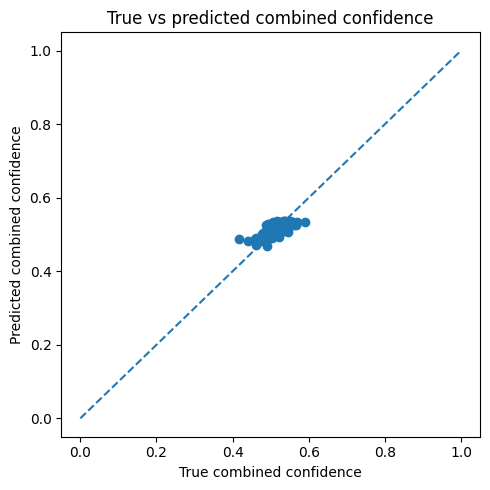

Saved: reporting\results\a14_combined_true_vs_predicted.png


In [22]:
plt.figure(figsize=(5, 5))
plt.scatter(
    practical_eval_df["true_combined_confidence"],
    practical_eval_df["predicted_combined_confidence"],
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("True vs predicted combined confidence")
plt.xlabel("True combined confidence")
plt.ylabel("Predicted combined confidence")
plt.tight_layout()

scatter_path = output_dir / "a14_combined_true_vs_predicted.png"
plt.savefig(scatter_path, dpi=150)
plt.show()

print("Saved:", scatter_path)

## Manual good/bad/ugly label template

The objective confidence scores are only one part of A14.

The assignment also asks the group to define labeling criteria and share labels.

Suggested manual scale:

- `5 = good recording`: skeleton stable, joints mostly correct, little/no flickering
- `4 = acceptable recording`: minor issues but usable
- `3 = borderline recording`: visible instability but may still be usable
- `2 = bad/ugly recording`: several wrong joints or frequent flickering
- `1 = very ugly recording`: unusable skeleton, severe joint errors or flickering

Each group member should label the same subset of recordings.  
Then compare labels and settle on criteria that maximize inter-rater agreement.

In [23]:
manual_label_template_df = kept_catalog_df[
    [
        "sequence_id",
        "path",
        "n_frames",
        "target_pose_confidence",
        "target_keypoint_confidence",
        "target_combined_confidence",
        "min_keypoint_confidence",
        "p10_keypoint_confidence",
        "fraction_keypoints_below_030",
        "fraction_frames_with_any_keypoint_below_030",
        "pose_score_source",
    ]
].copy()

manual_label_template_df["manual_goodness_score_1_to_5"] = ""
manual_label_template_df["manual_label_good_bad_ugly"] = ""
manual_label_template_df["rater_name"] = ""
manual_label_template_df["comment"] = ""

manual_label_template_path = output_dir / "a14_manual_good_bad_ugly_label_template.csv"
manual_label_template_df.to_csv(manual_label_template_path, index=False)

display(manual_label_template_df.head())

print("Saved manual label template:")
print(manual_label_template_path)

,sequence_id,path,n_frames,target_pose_confidence,target_keypoint_confidence,target_combined_confidence,min_keypoint_confidence,p10_keypoint_confidence,fraction_keypoints_below_030,fraction_frames_with_any_keypoint_below_030,pose_score_source,manual_goodness_score_1_to_5,manual_label_good_bad_ugly,rater_name,comment
0,A1,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,229,0.589341,0.589341,0.589341,0.1516,0.41990,0.012429,0.148472,mean_keypoint_fallback,,,,
1,G01,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,254,0.546313,0.546313,0.546313,0.1342,0.36831,0.039976,0.401575,mean_keypoint_fallback,,,,
2,G02,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,314,0.554782,0.554782,0.554782,0.0511,0.37742,0.050710,0.423567,mean_keypoint_fallback,,,,
3,G03,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,250,0.547615,0.547615,0.547615,0.0435,0.35049,0.063692,0.420000,mean_keypoint_fallback,,,,
4,G04,..\..\data\processed\Good_vs_Bad_movenet\csv_o...,219,0.493673,0.493673,0.493673,0.0232,0.21594,0.154197,0.666667,mean_keypoint_fallback,,,,


Saved manual label template:
reporting\results\a14_manual_good_bad_ugly_label_template.csv


### Manuall inspection  

In [25]:
# Evaluate all recordings with the trained combined model and sample 20 for manual review

from IPython.display import display, HTML, Video
from pathlib import Path
import random

# Settings for manual review
N_MANUAL_REVIEW = 20
MANUAL_REVIEW_RANDOM_SEED = 42
RENDER_VIDEO_PREVIEWS = True  # Change to False if the notebook becomes slow

# Candidate folders where the original videos may exist.
# Add/change paths here if your videos are stored somewhere else.
VIDEO_DIR_CANDIDATES = [
    Path("../../data/raw/all_videos"),
    Path("../../data/raw/Good_vs_Bad"),
    Path("../../data/raw/Good_vs_Bad/videos"),
    Path("../../../data/raw/all_videos"),
    Path("../../../data/raw/Good_vs_Bad"),
    Path("../../../data/raw/Good_vs_Bad/videos"),
]

VIDEO_EXTENSIONS = [
    ".mp4",
    ".mov",
    ".avi",
    ".mkv",
    ".webm",
]


def find_matching_video_path(sequence_id: str) -> str | None:
    """
    Finds the original video file matching a sequence_id.

    It first checks exact stem matches, for example:
    G01.csv -> G01.mp4

    If no exact match is found, it checks whether the sequence_id is contained
    in the video filename.
    """
    for video_dir in VIDEO_DIR_CANDIDATES:
        if not video_dir.exists():
            continue

        # Exact match first
        for ext in VIDEO_EXTENSIONS:
            candidate = video_dir / f"{sequence_id}{ext}"
            if candidate.exists():
                return str(candidate)

        # Fallback: sequence_id contained in filename
        for video_path in video_dir.rglob("*"):
            if video_path.suffix.lower() in VIDEO_EXTENSIONS:
                if sequence_id.lower() in video_path.stem.lower():
                    return str(video_path)

    return None


def evaluate_all_recordings_with_logged_model(model_uri: str) -> pd.DataFrame:
    """
    Runs the final logged MLflow pyfunc model on all kept recordings.

    Output contains:
    - true objective confidence labels
    - predicted pose/keypoint/combined confidence
    - absolute errors
    - accept/warn/reject decision
    - paths for manual review
    """
    loaded_model = mlflow.pyfunc.load_model(model_uri)

    rows = []

    for _, row in kept_catalog_df.iterrows():
        sequence_id = row["sequence_id"]
        csv_path = row["path"]

        raw_df = pd.read_csv(csv_path)
        raw_df["sequence_id"] = sequence_id

        pred_df = loaded_model.predict(raw_df)

        true_pose = float(row["target_pose_confidence"])
        true_keypoint = float(row["target_keypoint_confidence"])
        true_combined = float(row["target_combined_confidence"])

        pred_pose = float(pred_df["predicted_pose_confidence"].iloc[0])
        pred_keypoint = float(pred_df["predicted_keypoint_confidence"].iloc[0])
        pred_combined = float(pred_df["weighted_combined_confidence"].iloc[0])

        rows.append({
            "sequence_id": sequence_id,
            "csv_path": csv_path,
            "video_path": find_matching_video_path(sequence_id),
            "n_frames": int(row["n_frames"]),
            "pose_score_source": row.get("pose_score_source", "unknown"),

            "true_pose_confidence": true_pose,
            "predicted_pose_confidence": pred_pose,
            "pose_absolute_error": abs(true_pose - pred_pose),

            "true_keypoint_confidence": true_keypoint,
            "predicted_keypoint_confidence": pred_keypoint,
            "keypoint_absolute_error": abs(true_keypoint - pred_keypoint),

            "true_combined_confidence": true_combined,
            "predicted_combined_confidence": pred_combined,
            "combined_absolute_error": abs(true_combined - pred_combined),

            "decision": pred_df["decision"].iloc[0],
        })

    return pd.DataFrame(rows)


# 1. Evaluate all recordings
all_video_eval_df = evaluate_all_recordings_with_logged_model(logged_model_uri)

all_video_eval_path = output_dir / "a14_all_video_model_predictions_for_manual_review.csv"
all_video_eval_df.to_csv(all_video_eval_path, index=False)

print("Evaluated recordings:", len(all_video_eval_df))
print("Saved all predictions to:")
print(all_video_eval_path)

display(
    all_video_eval_df[
        [
            "sequence_id",
            "decision",
            "true_combined_confidence",
            "predicted_combined_confidence",
            "combined_absolute_error",
            "video_path",
        ]
    ].head()
)

print()
print("Decision counts:")
display(all_video_eval_df["decision"].value_counts().to_frame("count"))

print()
print("Mean absolute errors:")
print("Pose MAE:", all_video_eval_df["pose_absolute_error"].mean())
print("Keypoint MAE:", all_video_eval_df["keypoint_absolute_error"].mean())
print("Combined MAE:", all_video_eval_df["combined_absolute_error"].mean())


# 2. Randomly sample 20 recordings for manual review
n_review = min(N_MANUAL_REVIEW, len(all_video_eval_df))

manual_review_sample_df = (
    all_video_eval_df
    .sample(n=n_review, random_state=MANUAL_REVIEW_RANDOM_SEED)
    .sort_values("predicted_combined_confidence")
    .reset_index(drop=True)
)

manual_review_sample_df["manual_goodness_score_1_to_5"] = ""
manual_review_sample_df["manual_label_good_bad_ugly"] = ""
manual_review_sample_df["manual_comment"] = ""

manual_review_sample_path = output_dir / "a14_random_20_manual_review_sample.csv"
manual_review_sample_df.to_csv(manual_review_sample_path, index=False)

print()
print(f"Random manual review sample: {n_review} recordings")
print("Saved review sample to:")
print(manual_review_sample_path)

display(
    manual_review_sample_df[
        [
            "sequence_id",
            "decision",
            "predicted_pose_confidence",
            "predicted_keypoint_confidence",
            "predicted_combined_confidence",
            "true_combined_confidence",
            "combined_absolute_error",
            "video_path",
            "manual_goodness_score_1_to_5",
            "manual_label_good_bad_ugly",
            "manual_comment",
        ]
    ]
)


# 3. Show video previews for manual review, if video files were found
if RENDER_VIDEO_PREVIEWS:
    print()
    print("Video previews for manual review:")

    for idx, row in manual_review_sample_df.iterrows():
        sequence_id = row["sequence_id"]
        video_path = row["video_path"]

        title_html = f"""
        <hr>
        <h3>{idx + 1}. Sequence: {sequence_id}</h3>
        <p>
            <b>Decision:</b> {row["decision"]}<br>
            <b>Predicted pose confidence:</b> {row["predicted_pose_confidence"]:.3f}<br>
            <b>Predicted keypoint confidence:</b> {row["predicted_keypoint_confidence"]:.3f}<br>
            <b>Predicted combined confidence:</b> {row["predicted_combined_confidence"]:.3f}<br>
            <b>True combined confidence:</b> {row["true_combined_confidence"]:.3f}<br>
            <b>Combined absolute error:</b> {row["combined_absolute_error"]:.3f}
        </p>
        """

        display(HTML(title_html))

        if isinstance(video_path, str) and Path(video_path).exists():
            display(Video(video_path, embed=True, width=420))
        else:
            print("No matching video file found for this sequence.")
            print("CSV path:", row["csv_path"])
else:
    print()
    print("Video previews skipped because RENDER_VIDEO_PREVIEWS = False.")

Evaluated recordings: 114
Saved all predictions to:
reporting\results\a14_all_video_model_predictions_for_manual_review.csv


,sequence_id,decision,true_combined_confidence,predicted_combined_confidence,combined_absolute_error,video_path
0,A1,reject,0.589341,0.532837,0.056504,..\..\data\raw\all_videos\A1.avi
1,G01,reject,0.546313,0.507417,0.038897,None
2,G02,reject,0.554782,0.527217,0.027565,None
3,G03,reject,0.547615,0.531309,0.016307,None
4,G04,reject,0.493673,0.528886,0.035214,None



Decision counts:


,count
decision,
reject,114



Mean absolute errors:
Pose MAE: 0.015800910299284418
Keypoint MAE: 0.01583587182195563
Combined MAE: 0.01577104039882359

Random manual review sample: 20 recordings
Saved review sample to:
reporting\results\a14_random_20_manual_review_sample.csv


,sequence_id,decision,predicted_pose_confidence,predicted_keypoint_confidence,predicted_combined_confidence,true_combined_confidence,combined_absolute_error,video_path,manual_goodness_score_1_to_5,manual_label_good_bad_ugly,manual_comment
0,W28,reject,0.477217,0.487352,0.482284,0.460587,0.021697,None,,,
1,G63,reject,0.500745,0.505950,0.503347,0.480423,0.022924,None,,,
2,G57,reject,0.500796,0.507359,0.504077,0.517130,0.013053,None,,,
3,G46,reject,0.505052,0.505202,0.505127,0.522713,0.017586,None,,,
4,W02,reject,0.508427,0.510932,0.509680,0.487562,0.022118,None,,,
5,G36,reject,0.509932,0.511299,0.510616,0.521601,0.010985,None,,,
6,G55,reject,0.509712,0.512525,0.511119,0.518057,0.006939,None,,,
7,W13,reject,0.514028,0.516131,0.515079,0.530425,0.015345,None,,,
8,W42,reject,0.519210,0.520578,0.519894,0.544322,0.024428,None,,,
9,W11,reject,0.520434,0.524867,0.522651,0.516832,0.005819,None,,,


... (16 outputs left out)

No matching video file found for this sequence.
CSV path: ..\..\data\processed\Good_vs_Bad_movenet\csv_output\G50.csv


No matching video file found for this sequence.
CSV path: ..\..\data\processed\Good_vs_Bad_movenet\csv_output\G78.csv


No matching video file found for this sequence.
CSV path: ..\..\data\processed\Good_vs_Bad_movenet\csv_output\W10.csv


No matching video file found for this sequence.
CSV path: ..\..\data\processed\Good_vs_Bad_movenet\csv_output\G81.csv


In [26]:
# Threshold calibration without retraining
# This lets us test accept/warn/reject thresholds on the already predicted scores.

threshold_eval_df = all_video_eval_df.copy()

THRESHOLD_CANDIDATES = [
    {"accept_threshold": 0.55, "warn_threshold": 0.50},
    {"accept_threshold": 0.54, "warn_threshold": 0.50},
    {"accept_threshold": 0.53, "warn_threshold": 0.50},
    {"accept_threshold": 0.52, "warn_threshold": 0.49},
    {"accept_threshold": 0.51, "warn_threshold": 0.48},
]


def decision_from_threshold(score, accept_threshold, warn_threshold):
    if score >= accept_threshold:
        return "accept"
    if score >= warn_threshold:
        return "warn"
    return "reject"


threshold_rows = []

for candidate in THRESHOLD_CANDIDATES:
    accept_threshold = candidate["accept_threshold"]
    warn_threshold = candidate["warn_threshold"]

    decisions = threshold_eval_df["predicted_combined_confidence"].apply(
        lambda score: decision_from_threshold(
            score,
            accept_threshold=accept_threshold,
            warn_threshold=warn_threshold,
        )
    )

    counts = decisions.value_counts()

    threshold_rows.append({
        "accept_threshold": accept_threshold,
        "warn_threshold": warn_threshold,
        "n_accept": int(counts.get("accept", 0)),
        "n_warn": int(counts.get("warn", 0)),
        "n_reject": int(counts.get("reject", 0)),
        "accept_fraction": float(counts.get("accept", 0) / len(decisions)),
        "warn_fraction": float(counts.get("warn", 0) / len(decisions)),
        "reject_fraction": float(counts.get("reject", 0) / len(decisions)),
    })

threshold_summary_df = pd.DataFrame(threshold_rows)

display(threshold_summary_df)

threshold_summary_path = output_dir / "a14_threshold_calibration_summary.csv"
threshold_summary_df.to_csv(threshold_summary_path, index=False)

print("Saved:", threshold_summary_path)

,accept_threshold,warn_threshold,n_accept,n_warn,n_reject,accept_fraction,warn_fraction,reject_fraction
0,0.55,0.50,0,97,17,0.000000,0.850877,0.149123
1,0.54,0.50,0,97,17,0.000000,0.850877,0.149123
2,0.53,0.50,22,75,17,0.192982,0.657895,0.149123
3,0.52,0.49,55,48,11,0.482456,0.421053,0.096491
4,0.51,0.48,77,35,2,0.675439,0.307018,0.017544


Saved: reporting\results\a14_threshold_calibration_summary.csv


confusion matrix, auc roc curve?

## Conclusion draft

This notebook merged the keypoint-confidence and pose-confidence branches for A14.

### Deep Learning steps

The notebook followed the required Deep Learning steps:

1. Loaded MoveNet recordings.
2. Extracted pose confidence and keypoint confidence.
3. Calculated whole-recording confidence labels.
4. Used only the first `c = 10` frames as predictors.
5. Trained Dense, CNN, and LSTM regression models.
6. Evaluated MAE, MSE, RMSE, R², parameter count, estimated operations, and prediction time.
7. Logged the final champion model to MLflow with a reusable pyfunc wrapper.

### Objective labeling

The objective labels were:

- `target_pose_confidence`
- `target_keypoint_confidence`
- `target_combined_confidence`

The combined confidence was calculated as:

`0.5 * pose_confidence + 0.5 * keypoint_confidence`

### Practical application context

The model predicts recording quality from only the first frames.  
This means the system can warn or reject recordings early before the complete exercise pipeline is executed.

The final logged MLflow model returns:

- predicted pose confidence
- predicted keypoint confidence
- combined confidence
- practical decision: accept, warn, or reject

### Dead ends and limitations to discuss

If the raw CSV files do not contain an explicit pose-confidence column, the notebook approximates pose confidence as the mean keypoint confidence per frame.

In that case, the pose-confidence and keypoint-confidence targets become very similar.  
This should be discussed as a limitation, and the final system should preferably use a real pose-confidence value from the MoveNet/PoseNet extraction step.